In [1]:
import pandas as pd
import numpy as np
from google.colab import files
from IPython.display import display

# Upload the original, uncleaned CSV
uploaded = files.upload()

filename = next(iter(uploaded))

# Preserve the raw dataset unchanged
df_raw = pd.read_csv(filename)

# Create a separate working copy for cleaning
df = df_raw.copy(deep=True)

print("Raw dataset loaded successfully.")
print("Raw dataset shape:", df_raw.shape)
print("Working copy shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Saving Global temperature anomalies dataset.zip to Global temperature anomalies dataset.zip
Raw dataset loaded successfully.
Raw dataset shape: (100000, 26)
Working copy shape: (100000, 26)

First five rows:


,Country,Year,Temperature_Anomaly,CO2_Emissions,Population,Forest_Area,GDP,Renewable_Energy_Usage,Methane_Emissions,Sea_Level_Rise,...,Waste_Management,Per_Capita_Emissions,Industrial_Activity,Air_Pollution_Index,Biodiversity_Index,Ocean_Acidification,Fossil_Fuel_Usage,Energy_Consumption_Per_Capita,Policy_Score,Average_Temperature
0,Country_103,1913,-1.163537,8.876061e+08,1.627978e+08,54.872178,6.139887e+12,76.710013,8.317626e+06,8.111839,...,82.691409,2.285351,4.060975,150.285539,90.073356,8.025470,39.163860,1480.164332,78.870012,20.825292
1,Country_180,1950,-0.432122,4.497517e+08,4.281359e+08,84.051006,2.601447e+12,68.450021,6.206540e+06,42.025915,...,59.322883,17.411668,85.300604,27.305922,88.289837,8.021719,28.252554,1482.730048,32.600905,28.720587
2,Country_93,2014,0.444954,4.579080e+08,4.926732e+08,72.295357,5.192677e+12,36.725699,1.056885e+06,20.953840,...,94.982931,12.039703,83.804880,216.911429,86.936256,7.647408,61.548382,706.918809,37.671300,15.014084
3,Country_15,2020,-1.171616,5.049503e+08,1.252169e+09,17.259684,8.252128e+12,77.547901,1.986813e+06,45.599595,...,62.064250,2.853957,47.014265,35.869182,44.904331,7.569353,82.423750,2616.238324,86.581725,-1.277086
4,Country_107,1964,-0.564038,6.898891e+08,2.932960e+08,44.438605,8.560746e+12,10.019576,3.313252e+06,7.652150,...,84.431279,19.801173,89.379613,284.263093,8.102916,8.015415,29.964450,4975.683780,20.618406,2.861989



Column names:
['Country', 'Year', 'Temperature_Anomaly', 'CO2_Emissions', 'Population', 'Forest_Area', 'GDP', 'Renewable_Energy_Usage', 'Methane_Emissions', 'Sea_Level_Rise', 'Arctic_Ice_Extent', 'Urbanization', 'Deforestation_Rate', 'Extreme_Weather_Events', 'Average_Rainfall', 'Solar_Energy_Potential', 'Waste_Management', 'Per_Capita_Emissions', 'Industrial_Activity', 'Air_Pollution_Index', 'Biodiversity_Index', 'Ocean_Acidification', 'Fossil_Fuel_Usage', 'Energy_Consumption_Per_Capita', 'Policy_Score', 'Average_Temperature']


In [2]:
# Step 2: Identify potential cleaning targets
# This is an inspection step; it does not modify the data.

print("RAW DATASET BASELINE")
print("-" * 40)
print("Rows:", len(df_raw))
print("Columns:", len(df_raw.columns))
print("Missing cells:", int(df_raw.isna().sum().sum()))
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))

print("\nMissing values by column:")
missing_summary = df_raw.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0])

print("\nCountry formatting:")
country_values = df_raw["Country"].astype("string")
print("Country values with leading/trailing whitespace:",
      int((country_values != country_values.str.strip()).sum()))

print("\nData types:")
display(df_raw.dtypes.to_frame("Data type"))

print("\nRepeated Country-Year combinations:")
print("Repeated combinations:",
            int(df_raw.duplicated(subset=["Country", "Year"], keep=False).sum()))

print("\nPotential issue: repeated Country-Year combinations are not automatically duplicates.")
print("We will investigate them before deciding whether any action is needed.")

RAW DATASET BASELINE
----------------------------------------
Rows: 100000
Columns: 26
Missing cells: 12000
Exact duplicate rows: 0

Missing values by column:


,0
Energy_Consumption_Per_Capita,2000
Fossil_Fuel_Usage,2000
Policy_Score,2000
Average_Temperature,2000
Ocean_Acidification,2000
Biodiversity_Index,2000



Country formatting:
Country values with leading/trailing whitespace: 0

Data types:


,Data type
Country,object
Year,int64
Temperature_Anomaly,float64
CO2_Emissions,float64
Population,float64
Forest_Area,float64
GDP,float64
Renewable_Energy_Usage,float64
Methane_Emissions,float64
Sea_Level_Rise,float64



Repeated Country-Year combinations:
Repeated combinations: 98366

Potential issue: repeated Country-Year combinations are not automatically duplicates.
We will investigate them before deciding whether any action is needed.


In [3]:
# Inspect missingness patterns before choosing an imputation method

missing_cols = df.columns[df.isna().any()].tolist()

print("Columns containing missing values:")
print(missing_cols)

print("\nMissing-value percentage:")
missing_percent = (df[missing_cols].isna().mean() * 100).round(2)
display(missing_percent.to_frame("Missing_Percentage"))

print("\nDescriptive statistics before imputation:")
display(df[missing_cols].describe().T)

print("\nRows missing more than one value among these columns:")
missing_per_row = df[missing_cols].isna().sum(axis=1)
print("Rows with 2 or more missing values:", int((missing_per_row >= 2).sum()))
print("Rows with all 6 values missing:", int((missing_per_row == 6).sum()))

Columns containing missing values:
['Biodiversity_Index', 'Ocean_Acidification', 'Fossil_Fuel_Usage', 'Energy_Consumption_Per_Capita', 'Policy_Score', 'Average_Temperature']

Missing-value percentage:


,Missing_Percentage
Biodiversity_Index,2.0
Ocean_Acidification,2.0
Fossil_Fuel_Usage,2.0
Energy_Consumption_Per_Capita,2.0
Policy_Score,2.0
Average_Temperature,2.0



Descriptive statistics before imputation:


,count,mean,std,min,25%,50%,75%,max
Biodiversity_Index,98000.0,49.981122,28.863991,0.001155,24.937380,50.097524,74.813613,99.999568
Ocean_Acidification,98000.0,8.000386,0.288655,7.500007,7.750257,8.001393,8.249049,8.499991
Fossil_Fuel_Usage,98000.0,49.997963,28.900204,0.000688,24.962573,50.012808,75.078507,99.999789
Energy_Consumption_Per_Capita,98000.0,2547.993027,1416.496311,100.031306,1320.219583,2546.616430,3775.097658,4999.981227
Policy_Score,98000.0,49.988004,28.837057,0.003098,25.023471,49.957149,74.900395,99.999622
Average_Temperature,98000.0,15.033006,14.430887,-9.999950,2.569780,15.032100,27.524841,39.998836



Rows missing more than one value among these columns:
Rows with 2 or more missing values: 568
Rows with all 6 values missing: 0


In [4]:
# Step 4: Apply median imputation to columns with missing values

missing_cols = df.columns[df.isna().any()].tolist()

# Store medians before imputation for documentation
imputation_medians = df[missing_cols].median()

# Fill missing values in the working copy only
df[missing_cols] = df[missing_cols].fillna(imputation_medians)

print("Missing values after median imputation:")
display(df[missing_cols].isna().sum().to_frame("Remaining_Missing_Values"))

print("\nTotal missing cells before:", int(df_raw.isna().sum().sum()))
print("Total missing cells after:", int(df.isna().sum().sum()))

print("\nMedian values used:")
display(imputation_medians.to_frame("Median_Used"))

Missing values after median imputation:


,Remaining_Missing_Values
Biodiversity_Index,0
Ocean_Acidification,0
Fossil_Fuel_Usage,0
Energy_Consumption_Per_Capita,0
Policy_Score,0
Average_Temperature,0



Total missing cells before: 12000
Total missing cells after: 0

Median values used:


,Median_Used
Biodiversity_Index,50.097524
Ocean_Acidification,8.001393
Fossil_Fuel_Usage,50.012808
Energy_Consumption_Per_Capita,2546.616430
Policy_Score,49.957149
Average_Temperature,15.032100


In [11]:
# Step 5: Detect potential outliers using the IQR method

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
outlier_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = int(
                                ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
                                    )

    outlier_results.append({
                                                "Column": col,
                                                        "Q1": q1,
                                                                "Q3": q3,
                                                                        "IQR": iqr,
                                                                                "Lower_Bound": lower_bound,
                                                                                        "Upper_Bound": upper_bound,
                                                                                                "Potential_Outliers": outlier_count,
                                                                                                        "Outlier_Percentage": round(
                                                                                                                    outlier_count / len(df) * 100, 2
                                                                                                                            )
                                                                                                                                })

                                                                                                                                # Rebuild the complete summary
outlier_summary = pd.DataFrame(outlier_results)

print("Numeric columns checked:", len(numeric_cols))
print("Columns in summary:", len(outlier_summary))

display(
                                                                                                                                    outlier_summary.sort_values(
                                                                                                                                            "Potential_Outliers",
                                                                                                                                                    ascending=False
                                                                                                                                                        ).reset_index(drop=True)
                                                                                                                                                        )

Numeric columns checked: 25
Columns in summary: 25


,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Potential_Outliers,Outlier_Percentage
0,Year,1.930000e+03,1.992000e+03,6.200000e+01,1.837000e+03,2.085000e+03,0,0.0
1,Temperature_Anomaly,-9.994490e-01,9.980670e-01,1.997516e+00,-3.995723e+00,3.994341e+00,0,0.0
2,CO2_Emissions,2.504223e+08,7.506318e+08,5.002095e+08,-4.998919e+08,1.500946e+09,0,0.0
3,Population,3.762545e+08,1.125222e+09,7.489676e+08,-7.471969e+08,2.248673e+09,0,0.0
4,Forest_Area,2.496040e+01,7.489830e+01,4.993790e+01,-4.994645e+01,1.498051e+02,0,0.0
5,GDP,2.507503e+12,7.489082e+12,4.981579e+12,-4.964866e+12,1.496145e+13,0,0.0
6,Renewable_Energy_Usage,2.530224e+01,7.509594e+01,4.979370e+01,-4.938831e+01,1.497865e+02,0,0.0
7,Methane_Emissions,2.501312e+06,7.507855e+06,5.006542e+06,-5.008501e+06,1.501767e+07,0,0.0
8,Sea_Level_Rise,8.739127e+00,3.633315e+01,2.759402e+01,-3.265191e+01,7.772419e+01,0,0.0
9,Arctic_Ice_Extent,4.504867e+00,1.149950e+01,6.994635e+00,-5.987086e+00,2.199146e+01,0,0.0


In [12]:
# Step 6: Check important data constraints

checks = {
    "Year before 1900": (df["Year"] < 1900).sum(),
        "Year after 2023": (df["Year"] > 2023).sum(),
            "Negative Biodiversity_Index": (df["Biodiversity_Index"] < 0).sum(),
                "Biodiversity_Index above 100": (df["Biodiversity_Index"] > 100).sum(),
                    "Negative Ocean_Acidification": (df["Ocean_Acidification"] < 0).sum(),
                        "Negative Average_Temperature": (df["Average_Temperature"] < 0).sum(),
                            "Negative CO2_Emissions": (df["CO2_Emissions"] < 0).sum(),
                                "Negative Population": (df["Population"] < 0).sum(),
                                    "Negative GDP": (df["GDP"] < 0).sum(),
                                    }

for check, count in checks.items():
                                        print(f"{check}: {count}")

Year before 1900: 0
Year after 2023: 0
Negative Biodiversity_Index: 0
Biodiversity_Index above 100: 0
Negative Ocean_Acidification: 0
Negative Average_Temperature: 19517
Negative CO2_Emissions: 0
Negative Population: 0
Negative GDP: 0


In [13]:
# Inspect both temperature columns

print("Average_Temperature:")
display(df["Average_Temperature"].describe())

print("\nTemperature_Anomaly:")
display(df["Temperature_Anomaly"].describe())

print("\nSample rows with negative average temperature:")
display(
    df.loc[
            df["Average_Temperature"] < 0,
                    ["Country", "Year", "Average_Temperature", "Temperature_Anomaly"]
                        ].head(10)
                        )

Average_Temperature:


,Average_Temperature
count,100000.000000
mean,15.032988
std,14.285848
min,-9.999950
25%,2.814532
50%,15.032100
75%,27.264456
max,39.998836



Temperature_Anomaly:


,Temperature_Anomaly
count,100000.000000
mean,0.002647
std,1.154579
min,-1.999981
25%,-0.999449
50%,0.003523
75%,0.998067
max,1.999958



Sample rows with negative average temperature:


,Country,Year,Average_Temperature,Temperature_Anomaly
3,Country_15,2020,-1.277086,-1.171616
6,Country_189,1921,-7.786539,-1.362100
8,Country_103,1989,-5.829195,0.541387
11,Country_88,1929,-3.341789,0.568344
16,Country_131,1932,-3.669669,0.042703
18,Country_53,1904,-6.029725,-1.496030
19,Country_2,1997,-3.464813,-0.906048
22,Country_38,1961,-8.837851,-1.398815
23,Country_130,1994,-0.181665,-1.558742
30,Country_89,1966,-3.082258,1.573514


In [14]:
# Step 7: Check repeated Country-Year combinations

country_year_counts = df.groupby(
    ["Country", "Year"]
    ).size()

repeated_combinations = country_year_counts[
        country_year_counts > 1
        ]

print("Unique Country-Year combinations:", len(country_year_counts))
print("Repeated Country-Year combinations:", len(repeated_combinations))
print(
            "Rows belonging to repeated combinations:",
                int(repeated_combinations.sum())
                )

display(repeated_combinations.head(10))

Unique Country-Year combinations: 23797
Repeated Country-Year combinations: 22163
Rows belonging to repeated combinations: 98366


Country    Year
Country_1  1900    4
           1901    2
           1902    3
           1903    4
           1904    3
           1905    5
           1906    4
           1907    3
           1908    5
           1909    3
dtype: int64

In [15]:
# Step 8: Inspect repeated Country-Year combinations

df_sorted = df.sort_values(["Country", "Year"])

repeated_rows = df_sorted[
    df_sorted.duplicated(
            subset=["Country", "Year"],
                    keep=False
                        )
                        ]

display(
                            repeated_rows[
                                    [
                                                "Country",
                                                            "Year",
                                                                        "Average_Temperature",
                                                                                    "Temperature_Anomaly",
                                                                                                "CO2_Emissions",
                                                                                                            "Population"
                                                                                                                    ]
                                                                                                                        ].head(20)
                                                                                                                        )

,Country,Year,Average_Temperature,Temperature_Anomaly,CO2_Emissions,Population
17849,Country_1,1900,1.096845,0.868484,7.737906e+08,5.443298e+08
41919,Country_1,1900,16.997096,-1.522098,6.083792e+08,2.020119e+08
84743,Country_1,1900,-9.319760,-1.458531,5.735942e+05,1.961684e+08
86328,Country_1,1900,13.235857,0.772039,2.111143e+08,5.576762e+08
64631,Country_1,1901,7.210238,1.043901,9.882580e+08,5.083236e+08
77146,Country_1,1901,32.393594,-0.703154,6.998442e+08,1.494792e+09
13483,Country_1,1902,23.393363,1.883918,8.494816e+08,7.274409e+08
75629,Country_1,1902,10.595863,0.571906,7.474653e+08,8.694601e+07
79588,Country_1,1902,21.678715,-1.110650,5.300647e+08,2.669385e+08
18428,Country_1,1903,30.916126,1.603867,8.334240e+08,1.114425e+09


In [16]:
# Check how many countries and years are represented

print("Unique country labels:", df["Country"].nunique())
print("Minimum year:", df["Year"].min())
print("Maximum year:", df["Year"].max())

print("\nNumber of rows per country:")
display(df.groupby("Country").size().describe())

print("\nNumber of rows per year:")
display(df.groupby("Year").size().describe())

print("\nMost frequent Country-Year combinations:")
display(
    country_year_counts
        .sort_values(ascending=False)
            .head(10)
            )

Unique country labels: 195
Minimum year: 1900
Maximum year: 2023

Number of rows per country:


,0
count,195.000000
mean,512.820513
std,21.031973
min,457.000000
25%,498.000000
50%,516.000000
75%,528.000000
max,557.000000



Number of rows per year:


,0
count,124.000000
mean,806.451613
std,30.886721
min,732.000000
25%,783.000000
50%,803.000000
75%,832.500000
max,881.000000



Most frequent Country-Year combinations:


,,0
Country,Year,
Country_187,1900,15
Country_29,1960,14
Country_114,1959,14
Country_113,2015,14
Country_13,1994,13
Country_121,1941,13
Country_172,2013,13
Country_33,1940,13
Country_148,1946,13


In [20]:
# FINAL STEP: Cleaning log, before/after comparison, and export

import pandas as pd
import numpy as np

# 1. Create the before-and-after quality comparison
quality_comparison = pd.DataFrame({
    "Metric": [
            "Number of rows",
                    "Number of columns",
                            "Total missing cells",
                                    "Exact duplicate rows",
                                            "Country labels with whitespace",
                                                    "Repeated Country-Year combinations"
                                                        ],
                                                            "Before Cleaning": [
                                                                    len(df_raw),
                                                                            df_raw.shape[1],
                                                                                    int(df_raw.isna().sum().sum()),
                                                                                            int(df_raw.duplicated().sum()),
                                                                                                    int(
                                                                                                                df_raw["Country"].ne(
                                                                                                                                df_raw["Country"].astype(str).str.strip()
                                                                                                                                            ).sum()
                                                                                                                                                    ),
                                                                                                                                                            int(
                                                                                                                                                                        (df_raw.groupby(["Country", "Year"]).size() > 1).sum()
                                                                                                                                                                                )
                                                                                                                                                                                    ],
                                                                                                                                                                                        "After Cleaning": [
                                                                                                                                                                                                len(df),
                                                                                                                                                                                                        df.shape[1],
                                                                                                                                                                                                                int(df.isna().sum().sum()),
                                                                                                                                                                                                                        int(df.duplicated().sum()),
                                                                                                                                                                                                                                int(
                                                                                                                                                                                                                                            df["Country"].ne(
                                                                                                                                                                                                                                                            df["Country"].astype(str).str.strip()
                                                                                                                                                                                                                                                                        ).sum()
                                                                                                                                                                                                                                                                                ),
                                                                                                                                                                                                                                                                                        int(
                                                                                                                                                                                                                                                                                                    (df.groupby(["Country", "Year"]).size() > 1).sum()
                                                                                                                                                                                                                                                                                                            )
                                                                                                                                                                                                                                                                                                                ]
                                                                                                                                                                                                                                                                                                                })

print("BEFORE-AND-AFTER DATA QUALITY COMPARISON")
display(quality_comparison)

                                                                                                                                                                                                                                                                                                                # 2. Create the cleaning log
cleaning_log = pd.DataFrame([
                                                                                                                                                                                                                                                                                                                    {
                                                                                                                                                                                                                                                                                                                            "Issue": "Missing values",
                                                                                                                                                                                                                                                                                                                                    "Action": "Imputed missing numerical values using column medians",
                                                                                                                                                                                                                                                                                                                                            "Result": f"{int(df_raw.isna().sum().sum())} missing cells before; "
                                                                                                                                                                                                                                                                                                                                                              f"{int(df.isna().sum().sum())} after"
                                                                                                                                                                                                                                                                                                                                                                  },
                                                                                                                                                                                                                                                                                                                                                                      {
                                                                                                                                                                                                                                                                                                                                                                              "Issue": "Exact duplicate rows",
                                                                                                                                                                                                                                                                                                                                                                                      "Action": "Checked for exact duplicates; did not delete rows",
                                                                                                                                                                                                                                                                                                                                                                                              "Result": f"{int(df_raw.duplicated().sum())} exact duplicates in raw data"
                                                                                                                                                                                                                                                                                                                                                                                                  },
                                                                                                                                                                                                                                                                                                                                                                                                      {
                                                                                                                                                                                                                                                                                                                                                                                                              "Issue": "Potential outliers",
                                                                                                                                                                                                                                                                                                                                                                                                                      "Action": "Applied IQR detection; did not remove flagged values",
                                                                                                                                                                                                                                                                                                                                                                                                                              "Result": f"{int(outlier_summary['Potential_Outliers'].sum())} "
                                                                                                                                                                                                                                                                                                                                                                                                                                                "IQR-flagged values across the numeric columns"
                                                                                                                                                                                                                                                                                                                                                                                                                                                    },
                                                                                                                                                                                                                                                                                                                                                                                                                                                        {
                                                                                                                                                                                                                                                                                                                                                                                                                                                                "Issue": "Value constraints",
                                                                                                                                                                                                                                                                                                                                                                                                                                                                        "Action": "Checked years, index ranges, and negative values",
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                "Result": "No violations found in the checks performed, "
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  "except negative temperatures, which were retained"
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      },
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          {
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  "Issue": "Repeated Country-Year combinations",
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          "Action": "Investigated examples; retained records pending clarification",
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  "Result": f"{int((df.groupby(['Country', 'Year']).size() > 1).sum())} "
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    "repeated combinations remain"
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        },
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            {
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    "Issue": "Country labels",
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            "Action": "Checked leading and trailing whitespace",
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    "Result": "No whitespace issues found in the current dataset"
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        }
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        ])

print("\nCLEANING LOG")
display(cleaning_log)

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        # 3. Export the cleaned dataset and supporting reports
cleaned_filename = "Global_Warming_Fully_Cleaned.csv"

df.to_csv(cleaned_filename, index=False)
quality_comparison.to_csv("Before_After_Quality_Comparison.csv", index=False)
cleaning_log.to_csv("Week3_Cleaning_Log.csv", index=False)
outlier_summary.to_csv("IQR_Outlier_Summary.csv", index=False)

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        # 4. Verify the exported CSV
df_check = pd.read_csv(cleaned_filename)

print("\nEXPORT VERIFICATION")
print("Exported file:", cleaned_filename)
print("Original working DataFrame shape:", df.shape)
print("Reloaded CSV shape:", df_check.shape)
print("Missing cells in exported CSV:", int(df_check.isna().sum().sum()))
print("Exact duplicate rows in exported CSV:", int(df_check.duplicated().sum()))

assert df_check.shape == df.shape, "Shape mismatch after export!"
assert df_check.isna().sum().sum() == 0, "Missing values remain!"
assert list(df_check.columns) == list(df.columns), "Column mismatch!"

print("\nExport verification passed.")

BEFORE-AND-AFTER DATA QUALITY COMPARISON


,Metric,Before Cleaning,After Cleaning
0,Number of rows,100000,100000
1,Number of columns,26,26
2,Total missing cells,12000,0
3,Exact duplicate rows,0,0
4,Country labels with whitespace,0,0
5,Repeated Country-Year combinations,22163,22163



CLEANING LOG


,Issue,Action,Result
0,Missing values,Imputed missing numerical values using column ...,12000 missing cells before; 0 after
1,Exact duplicate rows,Checked for exact duplicates; did not delete rows,0 exact duplicates in raw data
2,Potential outliers,Applied IQR detection; did not remove flagged ...,0 IQR-flagged values across the numeric columns
3,Value constraints,"Checked years, index ranges, and negative values","No violations found in the checks performed, e..."
4,Repeated Country-Year combinations,Investigated examples; retained records pendin...,22163 repeated combinations remain
5,Country labels,Checked leading and trailing whitespace,No whitespace issues found in the current dataset



EXPORT VERIFICATION
Exported file: Global_Warming_Fully_Cleaned.csv
Original working DataFrame shape: (100000, 26)
Reloaded CSV shape: (100000, 26)
Missing cells in exported CSV: 0
Exact duplicate rows in exported CSV: 0

Export verification passed.


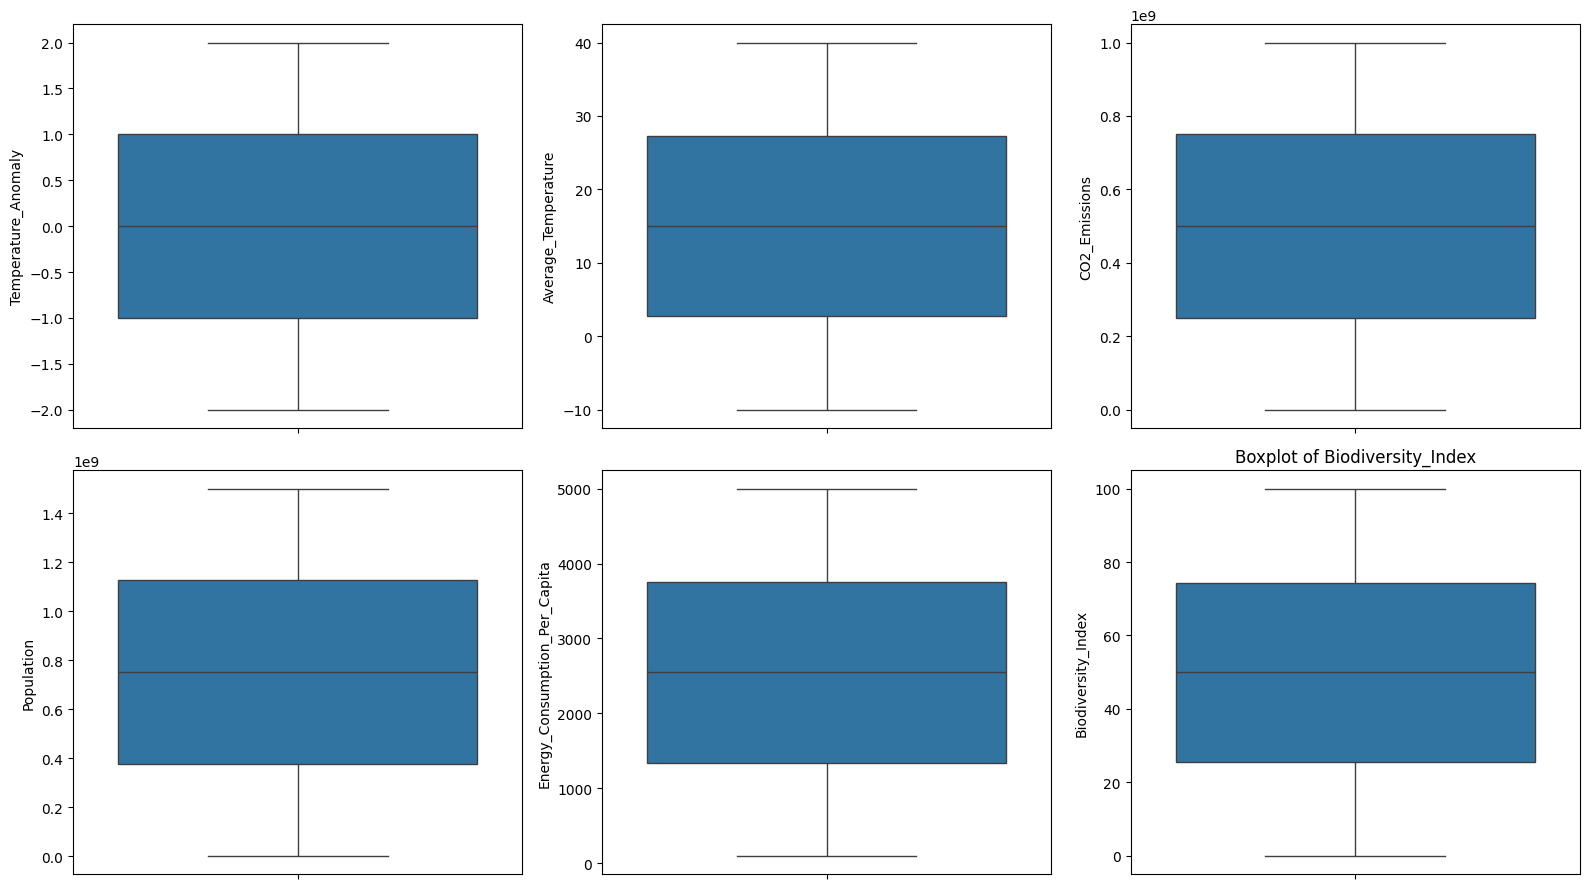

In [21]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select representative numerical columns
boxplot_cols = [
    "Temperature_Anomaly",
    "Average_Temperature",
    "CO2_Emissions",
    "Population",
    "Energy_Consumption_Per_Capita",
    "Biodiversity_Index"
]

# Draw boxplots using the cleaned dataset
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, boxplot_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()


In [23]:

import numpy as np
import pandas as pd
from scipy.stats import zscore

# Use all numerical columns except Year, which is a time identifier
zscore_cols = [
    col for col in df.select_dtypes(include=np.number).columns
        if col != "Year"
        ]

zscore_results = []

for col in zscore_cols:
            values = df[col]

            # Avoid division-by-zero for constant columns
            std = values.std(ddof=0)

            if std == 0 or pd.isna(std):
                z_scores = pd.Series(0, index=values.index)
            else:
                z_scores = (values - values.mean()) / std

            # Common threshold for potential outliers
            mask = z_scores.abs() > 3

            zscore_results.append({
                                                                "Column": col,
                                                                        "Z-score threshold": 3,
                                                                                "Potential outliers": int(mask.sum()),
                                                                                        "Minimum Z-score": z_scores.min(),
                                                                                                "Maximum Z-score": z_scores.max()
                                                                                                    })

zscore_summary = pd.DataFrame(zscore_results)

display(zscore_summary)


,Column,Z-score threshold,Potential outliers,Minimum Z-score,Maximum Z-score
0,Temperature_Anomaly,3,0,-1.734518,1.729912
1,CO2_Emissions,3,0,-1.733750,1.729179
2,Population,3,0,-1.730742,1.732153
3,Forest_Area,3,0,-1.736170,1.735304
4,GDP,3,0,-1.732776,1.735620
5,Renewable_Energy_Usage,3,0,-1.737448,1.729595
6,Methane_Emissions,3,0,-1.732440,1.730236
7,Sea_Level_Rise,3,0,-1.732955,1.724258
8,Arctic_Ice_Extent,3,0,-1.734020,1.732051
9,Urbanization,3,0,-1.730536,1.736163


In [25]:

print("IQR summary columns:")
print(outlier_summary.columns.tolist())

print("\nZ-score summary columns:")
print(zscore_summary.columns.tolist())

display(outlier_summary.head())


IQR summary columns:
['Column', 'Q1', 'Q3', 'IQR', 'Lower_Bound', 'Upper_Bound', 'Potential_Outliers', 'Outlier_Percentage']

Z-score summary columns:
['Column', 'Z-score threshold', 'Potential outliers', 'Minimum Z-score', 'Maximum Z-score']


,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Potential_Outliers,Outlier_Percentage
0,Year,1.930000e+03,1.992000e+03,6.200000e+01,1.837000e+03,2.085000e+03,0,0.0
1,Temperature_Anomaly,-9.994490e-01,9.980670e-01,1.997516e+00,-3.995723e+00,3.994341e+00,0,0.0
2,CO2_Emissions,2.504223e+08,7.506318e+08,5.002095e+08,-4.998919e+08,1.500946e+09,0,0.0
3,Population,3.762545e+08,1.125222e+09,7.489676e+08,-7.471969e+08,2.248673e+09,0,0.0
4,Forest_Area,2.496040e+01,7.489830e+01,4.993790e+01,-4.994645e+01,1.498051e+02,0,0.0


In [27]:

# Compare IQR and Z-score outlier counts
outlier_comparison = outlier_summary[
    ["Column", "Potential_Outliers"]
    ].merge(
        zscore_summary[["Column", "Potential outliers"]],
            on="Column",
                how="outer"
                )

outlier_comparison = outlier_comparison.rename(columns={
                    "Potential_Outliers": "IQR_Outliers",
                        "Potential outliers": "Z_Score_Outliers"
                        })

display(outlier_comparison)

print("\nTotal potential outliers detected:")
print("IQR method:", outlier_comparison["IQR_Outliers"].sum())
print("Z-score method:", outlier_comparison["Z_Score_Outliers"].sum())


,Column,IQR_Outliers,Z_Score_Outliers
0,Air_Pollution_Index,0,0.0
1,Arctic_Ice_Extent,0,0.0
2,Average_Rainfall,0,0.0
3,Average_Temperature,0,0.0
4,Biodiversity_Index,0,0.0
5,CO2_Emissions,0,0.0
6,Deforestation_Rate,0,0.0
7,Energy_Consumption_Per_Capita,0,0.0
8,Extreme_Weather_Events,0,0.0
9,Forest_Area,0,0.0



Total potential outliers detected:
IQR method: 0
Z-score method: 0.0
